In [1]:
from argparse import ArgumentParser, Namespace
import Spectral_Preprocessing as sp
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
parser = ArgumentParser()
parser.add_argument("--range-ir-1", dest= "wn_range_ir_1", default = (948,1860))
parser.add_argument("--range-ir-2", dest= "wn_range_ir_2", default = (2698,3002))

parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--finger-print-exl", dest= "finger_print_exl", type = bool, default = False)
parser.add_argument("--background-rule-ir", dest= "background_rule", type = str, default = 'mean')
parser.add_argument("--threshold-mean-intensity-ir", dest= "ths_mean_int_ir", type = float, default = 0)
parser.add_argument("--threshold-total-variation-intensity-ir", dest= "ths_tot_var_int_ir", type = float, default = 0)

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)


_StoreAction(option_strings=['--baseline'], dest='baseline', nargs=None, const=None, default=5, type=<class 'int'>, choices=None, required=False, help=None, metavar=None)

In [3]:
###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800)
args.wn_range_ir_2 = (2720, 2970)
args.range_min_ir = 674.9918 ###enter an integer
args.range_max_ir = 3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 1.929 ###enter an integer
args.finger_print_exl = False
args.background_rule = 'mean'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.64

args.range_min_raman = 355.555542 ###enter an integer or float 
args.range_max_raman = 3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.168021680216802 ###enter an integer or float

args.rubberband = 'als' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.
args.si_peak = 520 ###enter an integer or float

#directory_name = '/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/MEC_02_115/Raw Data/' ###directory where the PTIR files will be downloaded from.
directory_name = 'MEC_04_005/Raw Data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be included.

In [4]:
path = 'MEC_04_005/Raw Data/'
dirs = os.listdir(path)

for d in dirs:
    if d[-4:] == 'xlsx' or d==".DS_Store":
        del dirs[np.where(np.array(dirs) == d)[0][0]]

In [5]:
files_list = []
for d in dirs:
    dirs_2 = os.listdir(path + d)
    for d2 in dirs_2:
        if d2==".DS_Store":
            continue
        files = os.listdir(path + d + '/' + d2)
        files_list = files_list + [d + '/' + d2+'/'+f for f in files if f[-5:] == '.ptir']
    #files_list = files_list + [d+'/'+f for f in files if f[-5:] == '.ptir']

In [10]:
files_list

['July 2024/FHS_20240807/FHS_passive_July2024_D6_20240813.ptir',
 'July 2024/FHS_20240807/FHS_passive_July2024_D6_20240807.ptir',
 'July 2024/IAO_20240813/IAO_passive_July2024_F10_20240813.ptir',
 'July 2024/DC_20240806/DC_passive_July2024_I9_20240806.ptir',
 'July 2024/ICB_20240814/ICB_passive_July2024_C4_20240814.ptir',
 'May 2024/IAO_20240710/IAO_passive_May2024_H5_20240710.ptir',
 'May 2024/ICB_20240716/ICB_passive_May2024_B8_20240716.ptir',
 'May 2024/DC_20240702/DC_passive_May2024_D2_20240702.ptir',
 'May 2024/DC_20240702/DC_passive_May2024_D2_20240703.ptir',
 'May 2024/FHS_20240709/FHS_passive_May2024_F10_20240709.ptir',
 'March 2024/IAO_20240625/IAO_passive_MarApr2024_H9_20240625.ptir',
 'March 2024/ICB_20240619/ICB_passive_MarApr2024_G7_20240619.ptir',
 'March 2024/ICB_20240619/ICB_passive_MarApr2024_G7_20240702.ptir',
 'March 2024/FHS_20240618/FHS_passive_MarApr2024_I4_20240618.ptir',
 'March 2024/DC_20240612/DC_passive_MarApr2024_C9_20240612.ptir',
 'April 2024/DC_20240529/D

In [6]:
raman_final, ir_final, label_list, XX_ir, XX_raman, ids, coords, _, rng, ir_bg_label = sp.ptir_to_interpolated_processed_csv(args, directory_name,
                                                            ir_export_filename, raman_export_filename, 
                                                            file_list = files_list, transpose = True)


In [7]:
#ids_file_name = np.array([x[19:-5] 
#                 if x[7] == '/' else x[20:-5] 
#                 for x in ids])
#ids_file_name = np.array([x[19:-13] + x[-9:-5] 
#                 if x[7] == '/' else x[20:-17] + '_' + '-'+x[-17:-13] + x[-9:-5] # x[20:-5] 
#                 for x in ids])

ids_file_name = np.array([x[str.find(x, '/',20)+1:-5] for x in ids])

ids_file_name = ids_file_name.astype('<U40')
#ids_file_name_list = np.unique(ids_file_name)

idx_ = []
i = 1
for j, x in enumerate(ids_file_name):
    #idx_.append(i)
    ids_file_name[j] = x +'_'+ str(i)
    idx_.append(x +'_'+ str(i))
    if j < ids_file_name.shape[0]-1 and x != ids_file_name[j+1]:
        i = 1
    else:
        i = i + 1

ids_file_name

array(['FHS_passive_July2024_D6_20240813_1',
       'FHS_passive_July2024_D6_20240813_2',
       'FHS_passive_July2024_D6_20240813_3', ...,
       'IAO_passive_June2024_G7_20240801_41',
       'IAO_passive_June2024_G7_20240801_42',
       'IAO_passive_June2024_G7_20240801_43'], dtype='<U40')

In [11]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['id'] = ids_file_name
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir
preposs_data_ir.to_csv('passive_data/data_ir_passive_data.csv')

In [129]:
preposs_data_ir.to_csv('passive_data/data_ir_passive_data_total_var.csv')

In [12]:
np.mean(ir_bg_label == 'background')

0.4168956043956044

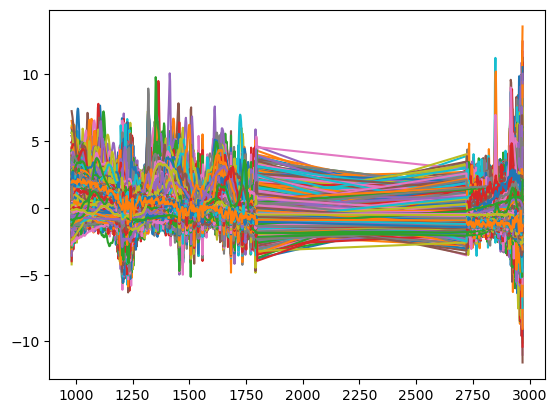

In [40]:
_ = plt.plot(XX_ir, 
             ir_final.T)